In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd

from ll import eps_V_t, eps_Y_t, obs_ll_t, latent_ll_t, obs_ll, latent_ll

In [3]:
# load data
SP500_df = pd.read_csv('SP500.csv')

# take log-diffs and drop nans
SP500_df['log_prices'] = SP500_df['SP500'].apply(lambda x: np.log(x))
SP500_df['log_returns'] = SP500_df['log_prices'].diff()

# set index
SP500_df['observation_date'] = pd.DatetimeIndex(SP500_df['observation_date'])
SP500_df = SP500_df.set_index('observation_date')

# print dates
print(f'Data from {SP500_df.index[0]} to {SP500_df.index[-1]}')

# drop nans -> inspect which is nans
SP500_df = SP500_df.dropna(subset=['log_prices'])

Data from 2016-09-19 00:00:00 to 2026-09-17 00:00:00


In [4]:
Delta = 1/252
T = len(SP500_df['log_prices'])
Y = SP500_df['log_prices'].to_numpy()
theta_init = SP500_df['log_returns'].var()/Delta

init_guess_Theta = {
    'mu' : 0.00,
    'kappa' : 1.0,
    'kappatheta' : theta_init,
    'sigma_sq_V' : 0.001,
    'rho' : -0.5,
}

init_guess_V = np.ones(T)*theta_init

priors = {

    # mu
    'mu_mu' : 0.0,
    'sigma_sq_mu' : 1.0,

    # kappa
    'mu_kappa' : 0.0,
    'sigma_sq_kappa' : 1.0,

    # kappatheta
    'mu_kappatheta' : 0.0,
    'sigma_sq_kappatheta' : 1.0,

    # sigma_V
    'alpha_sigma_sq_V' : 2.5,
    'beta_sigma_sq_V' : 0.1,

    # rho
    'rho_low' : -1,
    'rho_high' : 1
    
}

In [8]:
# from bayesian_regression import mu_regression, kappa_kappatheta_regression, sigma_sq_V_regression

# def mu_step(priors, Theta_fill, V):

#     # unpack other par
#     kappa = Theta_fill['kappa']
#     kappatheta = Theta_fill['kappatheta']
#     sigma_sq_V = Theta_fill['sigma_sq_V']
#     rho = Theta_fill['rho']

#     # do bayesian regression to obtain posterior density
#     mu_post, sigma_sq_post = mu_regression(priors, kappa, kappatheta, sigma_sq_V, rho, Y, V, Delta)

#     # draw normal
#     mu_new = np.random.normal(loc=mu_post, scale=np.sqrt(sigma_sq_post))

#     return mu_new

# def kappatheta_kappa_step(priors, Theta_fill, V):

#     # unpack other par
#     mu = Theta_fill['mu']
#     sigma_sq_V = Theta_fill['sigma_sq_V']
#     rho = Theta_fill['rho']

#     # do bayesian regression to obtain posterior density
#     Mu_post, Omega_post = kappa_kappatheta_regression(priors, mu, sigma_sq_V, rho, Y, V, Delta)

#     # draw normal
#     draws = np.random.multivariate_normal(mean=Mu_post.flatten(), cov=Omega_post)
#     kappatheta, kappa = draws[0].item(), draws[1].item()

#     return kappatheta, kappa

from Gibbs import mu_step, kappatheta_kappa_step

def sigma_V_step(priors, Theta, Theta_fill, V):

    # unpack prior and create prior density function
    alpha_sigma_sq_V_prior = priors['alpha_sigma_sq_V']
    beta_sigma_sq_V_prior = priors['beta_sigma_sq_V']
    prior_density = lambda x: stats.invgamma.logpdf(x, alpha_sigma_sq_V_prior, scale=beta_sigma_sq_V_prior)

    # unpack other par
    mu = Theta_fill['mu']
    kappa = Theta_fill['kappa']
    kappatheta = Theta_fill['kappatheta']
    rho = Theta_fill['rho']

    # do bayesian regression to obtain proposal draw and define proposal density
    alpha_sigma_sq_V_prop, beta_sigma_sq_V_prop = sigma_sq_V_regression(priors, kappa, kappatheta, V, Delta)
    sigma_sq_V_proposal = stats.invgamma.rvs(alpha_sigma_sq_V_prop, scale=beta_sigma_sq_V_prop)
    proposal_density = lambda x: stats.invgamma.logpdf(x, alpha_sigma_sq_V_prop, scale=beta_sigma_sq_V_prop)

    # unpack old MH-draw
    sigma_sq_V_g = Theta['sigma_sq_V']

    # do MH-step
    # posterior log density for gth draw
    obs_ll_g = obs_ll(mu, kappa, kappatheta, sigma_sq_V_g, rho, Y, V, Delta)
    latent_ll_g = latent_ll(kappa, kappatheta, sigma_sq_V_g, V, Delta)
    prior_g = prior_density(sigma_sq_V_g)
    post_g = obs_ll_g + latent_ll_g + prior_g

    # posterior log density for proposal draw
    obs_ll_proposal = obs_ll(mu, kappa, kappatheta, sigma_sq_V_proposal, rho, Y, V, Delta)
    latent_ll_proposal = latent_ll(kappa, kappatheta, sigma_sq_V_proposal, V, Delta)
    prior_proposal = prior_density(sigma_sq_V_proposal)
    post_proposal = obs_ll_proposal + latent_ll_proposal + prior_proposal

    # proposal density for gth draw
    proposal_dens_g = proposal_density(sigma_sq_V_g)

    # proposal density for proposal
    proposal_dens_proposal = proposal_density(sigma_sq_V_proposal)

    # compute log(alpha)
    log_alpha = post_proposal - post_g + proposal_dens_g - proposal_dens_proposal

    # accept if log(alpha) > log(u)
    u = np.random.uniform()
    logu = np.log(u)

    if log_alpha > logu:
        sigma_sq_V_gplus = sigma_sq_V_proposal

    else:
        sigma_sq_V_gplus = sigma_sq_V_g

    return sigma_sq_V_gplus

def rho_step(priors, Theta, Theta_fill, V):

    # unpack other par
    mu = Theta_fill['mu']
    kappa = Theta_fill['kappa']
    kappatheta = Theta_fill['kappatheta']
    sigma_sq_V = Theta_fill['sigma_sq_V']

    # obtain proposal
    Yt = np.array(SP500_df['log_prices'])[:-1] # T-1: Y1,Y2,...,YT-1
    Ytplus = np.array(SP500_df['log_prices'].shift(-1))[:-1] # T-1: Y2,Y3,...,YT
    Vt = V[:-1] # T-1: V1,V2,...,VT-1
    Vtplus = V[1:] # T-1: V2,V3,...,VT
    eps_Vt = eps_V_t(kappa, kappatheta, sigma_sq_V, Vt, Vtplus, Delta)
    eps_Yt = eps_Y_t(mu, Yt, Ytplus, Vt, Delta)

    rho_mean = np.corrcoef(eps_Vt, eps_Yt)[0,1].item()
    rho_std = ((1-rho_mean**2)/np.sqrt(T-1)).item()

    rho_proposal = np.random.normal(loc=rho_mean, scale=rho_std)

    # reject all proposals where rho is not in [-1,1]
    if np.abs(rho_proposal) > 1.00:
        return rho_g

    # unpack old MH-draw
    rho_g = Theta['rho']

    # do MH-step, prior is uninformative
    # posterior log density for gth draw, latent likelihood is unaffected by rho
    obs_ll_g = obs_ll(mu, kappa, kappatheta, sigma_sq_V, rho_g, Y, V, Delta)
    post_g = obs_ll_g

    # posterior log density for proposal draw
    obs_ll_proposal = obs_ll(mu, kappa, kappatheta, sigma_sq_V, rho_proposal, Y, V, Delta)
    post_proposal = obs_ll_proposal

    # proposal density for gth draw
    proposal_dens_g = stats.norm.logpdf(rho_g, loc=rho_mean, scale=rho_std)

    # proposal density for proposal draw
    proposal_dens_proposal = stats.norm.logpdf(rho_proposal, loc=rho_mean, scale=rho_std)

    # compute log(alpha)
    log_alpha = post_proposal - post_g + proposal_dens_g - proposal_dens_proposal

    # accept if log(alpha) > log(u)
    u = np.random.uniform()
    logu = np.log(u)

    if log_alpha > logu:
        rho_gplus = rho_proposal

    else:
        rho_gplus = rho_g

    return rho_gplus


def V_step(priors, Theta, Theta_fill, V):

    # par
    mu = Theta_fill['mu']
    kappa = Theta_fill['kappa']
    kappatheta = Theta_fill['kappatheta']
    sigma_sq_V = Theta_fill['sigma_sq_V']
    rho = Theta_fill['rho']

    # t = 1: p(Vt|Vt,Vt+1,Yt,Yt+1,Theta) = p(Yt+1-Yt|Vt,Vt+1,Theta) * p(Vt+1-Vt|Theta)
    # t = 2,3,...,T-1: p(Vt|Vt-1,Vt+1,Yt-1,Yt,Yt+1,Theta) = p(Yt+1-Y_t|Vt,Vt+1,Theta) * p(Yt-Yt-1|Vt-1,Vt,Theta) * p(Vt+1-Vt|Theta) * p(Vt-Vt-1|Theta)
    # t = T: p(Vt|Vt-1,Yt-1,Yt,Theta) = p(Yt-Yt-1|Vt-1,Vt,Theta) * p(Vt-Vt-1|Theta)
    
    # allocate
    V_gplus = np.zeros_like(V) + np.nan # T
    
    for t in range(0,T):

        if t == 0:
            Vbar = V[t+1]
        
        elif t == T-1:
            Vbar = V[t-1]

        else:
            Vbar = 0.5*(V[t-1]+V[t+1])

        Vt_g = V[t]
        rw_shock_t = np.random.normal(loc=0.0, scale=np.sqrt((sigma_sq_V*Vbar*Delta)/2))
        Vt_proposal = Vt_g + rw_shock_t

        # reject all proposal with negative variance
        if Vt_proposal < 0:
            V_gplus[t] = Vt_g
            continue

        # for t = 1 and t = 1,2,...,T-1 -> can always unpack next-period variance
        if t<T-1:

            Vtplus_g = V[t+1]

            # g likelihood in period t
            obs_llt_g = obs_ll_t(mu, kappa, kappatheta, sigma_sq_V, rho, Y[t], Y[t+1], Vt_g, Vtplus_g, Delta)
            latent_llt_g = latent_ll_t(kappa, kappatheta, sigma_sq_V, Vt_g, Vtplus_g, Delta)

            # proposal likelihood in period t
            obs_llt_proposal = obs_ll_t(mu, kappa, kappatheta, sigma_sq_V, rho, Y[t], Y[t+1], Vt_proposal, Vtplus_g, Delta)
            latent_llt_proposal = latent_ll_t(kappa, kappatheta, sigma_sq_V, Vt_proposal, Vtplus_g, Delta)

            # t = 1 -> can't unpack former period variance -> zero out ll for t-1
            if t == 0:
                obs_lltmimus_g, obs_lltminus_proposal = 0.0, 0.0
                latent_lltminus_g, latent_lltminus_proposal = 0.0, 0.0
        
        # for t = 1,2,...,T-1 and t = T -> can always unpack former period variance
        if t>0: 

            Vtminus_g = V_gplus[t-1]

            # g likelihood in period t-1
            obs_lltmimus_g = obs_ll_t(mu, kappa, kappatheta, sigma_sq_V, rho, Y[t-1], Y[t], Vtminus_g, Vt_g, Delta)
            latent_lltminus_g = latent_ll_t(kappa, kappatheta, sigma_sq_V, Vtminus_g, Vt_g, Delta)

            # proposal likelihood in period t-1
            obs_lltminus_proposal = obs_ll_t(mu, kappa, kappatheta, sigma_sq_V, rho, Y[t-1], Y[t], Vtminus_g, Vt_proposal, Delta)
            latent_lltminus_proposal = latent_ll_t(kappa, kappatheta, sigma_sq_V, Vtminus_g, Vt_proposal, Delta)

            # t = T -> can't unpack next period variance -> zero out ll for t
            if t == T-1:
                obs_llt_g, obs_llt_proposal = 0.0, 0.0
                latent_llt_g, latent_llt_proposal = 0.0, 0.0

        # compute posterior ll for both g and proposal
        post_g = obs_llt_g + latent_llt_g + obs_lltmimus_g + latent_lltminus_g
        post_proposal = obs_llt_proposal + latent_llt_proposal + obs_lltminus_proposal + latent_lltminus_proposal

        log_alpha = post_proposal - post_g

        # accept if log(alpha) > log(u)
        u = np.random.uniform()
        logu = np.log(u)

        if log_alpha > logu:
            Vt_gplus = Vt_proposal

        else:
            Vt_gplus = Vt_g

        V_gplus[t] = Vt_gplus

    return V_gplus

In [10]:
def cycle(Theta_g, V_g):

    # allocate
    Theta_fill = Theta_g.copy()

    # mu
    mu_gplus = mu_step(priors, Theta_fill, Y, V_g, Delta)
    Theta_fill['mu'] = mu_gplus

    # kappa, kappatheta
    kappatheta_gplus, kappa_gplus = kappatheta_kappa_step(priors, Theta_fill, Y, V_g, Delta)
    Theta_fill['kappatheta'] = kappatheta_gplus
    Theta_fill['kappa'] = kappa_gplus

    # sigma_sq_V
    sigma_sq_V_gplus = sigma_V_step(priors, Theta_g, Theta_fill, V_g)
    Theta_fill['sigma_sq_V'] = sigma_sq_V_gplus

    # rho
    rho_gplus = rho_step(priors, Theta_g, Theta_fill, V_g)
    Theta_fill['rho'] = rho_gplus

    # V
    V_gplus = V_step(priors, Theta_g, Theta_fill, V_g)

    return Theta_fill, V_gplus

In [11]:
G = 100000
mu_draws = np.zeros((G,)) + np.nan
kappa_draws = np.zeros((G,)) + np.nan
kappatheta_draws = np.zeros((G,)) + np.nan
sigma_sq_V_draws = np.zeros((G,)) + np.nan
rho_draws = np.zeros((G,)) + np.nan
V_draws = np.zeros((T,G)) + np.nan

for g in range(G):

    if (g % 10 == 0): print(f'g = {g}')

    if g == 0:
        Theta_g = init_guess_Theta
        V_g = init_guess_V

    Theta_g, V_g = cycle(Theta_g, V_g)

    mu_draws[g] = Theta_g['mu']
    kappa_draws[g] = Theta_g['kappa']
    kappatheta_draws[g] = Theta_g['kappatheta']
    sigma_sq_V_draws[g] = Theta_g['sigma_sq_V']
    rho_draws[g] = Theta_g['rho']
    V_draws[:,g] = V_g

g = 0
g = 10
g = 20
g = 30
g = 40
g = 50
g = 60
g = 70


KeyboardInterrupt: 

In [ ]:
np.nanmean(sigma_sq_V_draws)

np.float64(0.0037067634879575256)

(array([  7.,  44., 251., 285., 436., 109., 184., 344., 468.,  50., 402.,
        235., 257., 362., 273., 175.,  72.,  47.,   6.,  10.,   8.,   1.,
          4.,   1.,  12.,  14.,   6.,   7.,   9.,   5.,   1.,   7.,  17.,
          4.,   6.,   2.,   0.,   0.,  11.,   1.,   1.,   0.,   9.,   0.,
          8.,   5.,   8.,   8.,   5.,   7.,  16.,  28.,  27.,  32.,  30.,
         26.,  39.,  31.,  35.,  32.,  30.,  33.,  36.,  26.,  20.,  35.,
         11.,  16.,  10.,  14.,  18.,  15.,  30.,   2.,   3.,   6.,  12.,
          8.,   8.,   1.,   6.,   3.,   5.,   9.,   0.,   1.,   1.,   1.,
          1.,   4.,   0.,   1.,   0.,   0.,   0.,   2.,   0.,   1.,   0.,
          2.]),
 array([-0.85480283, -0.84914455, -0.84348628, -0.837828  , -0.83216972,
        -0.82651145, -0.82085317, -0.81519489, -0.80953662, -0.80387834,
        -0.79822007, -0.79256179, -0.78690351, -0.78124524, -0.77558696,
        -0.76992868, -0.76427041, -0.75861213, -0.75295386, -0.74729558,
        -0.7416373 , -0.73

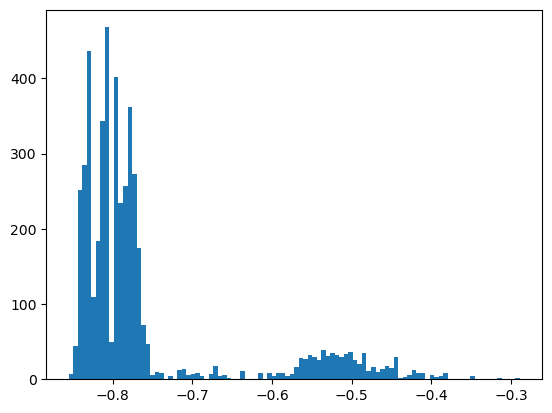

In [ ]:
plt.hist(rho_draws, bins=100)